# Avance semanal · 19 → 26 de septiembre de 2026

**Tesis:** Aprendizaje por refuerzo profundo aplicado a la Bolsa de Valores de Lima
· Rodrigo Holguín · Asesor: Dr. E. Villanueva · reunión del 28-sep-2026

---

## La semana en cinco líneas

1. **R8 (ablación de señales) quedó completo**: se corrió la vista `completa`.
   Resultado: **los canales se estorban** — juntos rinden menos que por separado.
2. **Se explicó por qué entrenar más empeora al agente**: la recompensa (DSR) **no
   ordena** las estrategias como el Sharpe en el tramo de entrenamiento.
3. **Se construyó un "tamiz" para elegir recompensa sin entrenar.** Un barrido fino
   encontró una recompensa admisible (`logret_dd`, λ ≈ 0.63–0.68) en el pliegue 0,
   pero **no es estable entre pliegues**.
4. **R7 multi-algoritmo**: el código de **SAC y DDPG** está listo y su exploración
   calibrada contra PPO. Falta fijar los valores y correr.
5. **Bloomberg**: 428 fechas de anuncio de resultados (A1 cerrado) y la prueba de
   liquidez **LQA**, que reveló que el modelo de costos usa un **spread constante y
   sin impacto de mercado** — es el siguiente frente de trabajo.

> ⚠️ **Cómo leer las cifras.** Todo es sobre **validación**, con **3 semillas**.
> El tramo de **prueba no se ha tocado** (`con_test = 0` en el registro). Lo que
> está establecido son los resultados **negativos**; ninguna diferencia positiva
> es hallazgo hasta la corrida definitiva de 10 semillas.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ART = RAIZ / "data" / "interim" / "artefactos_oe1"
BBG = RAIZ / "data" / "raw" / "bloomberg"
carga = lambda f: json.loads((ART / f).read_text(encoding="utf-8"))

plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False,
})
C = {"1N": "#2b6cb0", "caja": "#2f855a", "agente": "#c05621", "gris": "#a0aec0",
     "rojo": "#c53030", "morado": "#6b46c1", "oscuro": "#2d3748", "ok": "#38a169"}
pct = FuncFormatter(lambda v, _: f"{v:.0%}")
pct1 = FuncFormatter(lambda v, _: f"{v:.1%}")
METRICAS = ["retorno_total", "sharpe", "sortino", "max_drawdown", "rotacion_anual", "peso_caja_medio"]

def filas(archivo, etiqueta=None):
    # Aplana {vistas: {vista: {pliegueK: [por semilla]}}} a un DataFrame largo.
    d = carga(archivo)
    out = []
    for vista, por_pliegue in d["vistas"].items():
        for pl, semillas in por_pliegue.items():
            for s in semillas:
                out.append({"brazo": etiqueta or vista, "pliegue": int(pl[-1]),
                            "seed": s["seed"], **{m: s[m] for m in METRICAS}})
    return pd.DataFrame(out)

print("artefactos:", ART)

artefactos: C:\tesis\data\interim\artefactos_oe1


---
## 0 · Qué se mide y cómo leerlo

| Métrica | Qué es | Mejor si… |
|---|---|---|
| **Retorno total** | ganancia del portafolio en el año de validación, **neta de costos** | más alto |
| **Sharpe** | retorno en exceso de la caja ÷ volatilidad (anualizado) | más alto |
| **Sortino** | como Sharpe, pero solo penaliza la volatilidad a la baja | más alto |
| **Máx. drawdown** | la peor caída desde un pico | más cerca de 0 |
| **Rotación anual** | cuántas veces por año se "da vuelta" la cartera (→ costo) | más baja |
| **ρ de Spearman** | ¿la recompensa **ordena** las estrategias igual que el Sharpe? (−1 a +1) | cercano a +1 |
| **Diferencia pareada** | brazo − referencia, **misma semilla y mismo pliegue** (quita el ruido común) | según la métrica |

**Protocolo** (sin cambios): *walk-forward* de 3 pliegues con embargo de 20 días,
entrenamiento *expanding*, 3 semillas × 3 pliegues = **9 celdas** por configuración.
Los *baselines* (1/N, caja, Markowitz) corren **dentro del mismo simulador y con los
mismos costos** que el agente.

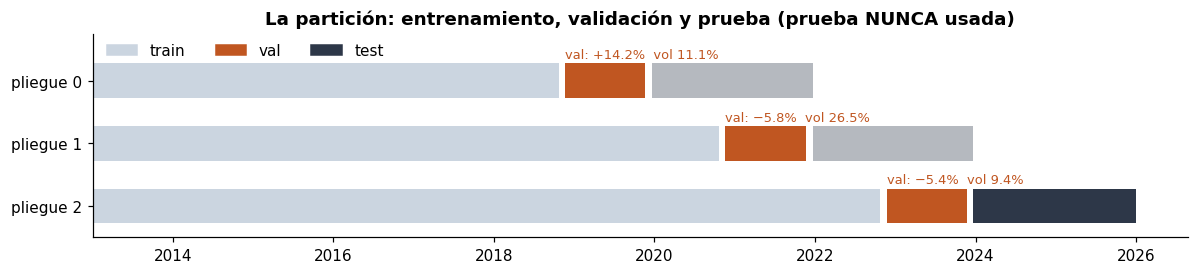

In [2]:
PL = carga("pliegues.json")["pliegues"]
reg = {0: "+14.2%  vol 11.1%", 1: "−5.8%  vol 26.5%", 2: "−5.4%  vol 9.4%"}   # caracteriza_pliegues.py
fig, ax = plt.subplots(figsize=(11, 2.6))
col = {"train": "#cbd5e0", "val": C["agente"], "test": C["oscuro"]}
for p in PL:
    y = 2 - p["idx"]
    for tramo in ("train", "val", "test"):
        a, b = pd.Timestamp(p[tramo]["desde"]), pd.Timestamp(p[tramo]["hasta"])
        ax.barh(y, (b - a).days, left=a, color=col[tramo], height=0.55,
                alpha=0.35 if tramo == "test" and p["idx"] < 2 else 1)
    v = pd.Timestamp(p["val"]["desde"])
    ax.text(v, y + 0.36, f"val: {reg[p['idx']]}", fontsize=8.5, color=C["agente"])
ax.set_yticks([2, 1, 0], ["pliegue 0", "pliegue 1", "pliegue 2"])
ax.grid(False); ax.set_title("La partición: entrenamiento, validación y prueba (prueba NUNCA usada)")
ax.legend(handles=[Patch(color=col[t], label=t) for t in col], loc="upper left", ncol=3, bbox_to_anchor=(0, 1.02))
ax.set_ylim(-.5, 2.75)
plt.tight_layout(); plt.show()

*Corrección de la semana:* el año de validación del pliegue 0 **no es "el mejor año de la
década"** como se había escrito: medido sobre el panel está en el **percentil 78** de
todas las ventanas de 252 días (la mejor rinde +69.9% y termina en feb-2017). Es "el más
favorable de los seis tramos de la partición". Corregido en todo el repo.

---
## 1 · R8 — ¿Qué canal de información le sirve al agente?

Cuatro vistas, cada una agrega **un solo canal** a la base de mercado (para que el
aporte sea atribuible), más la vista **`completa`** con los tres a la vez.
PPO · recompensa DSR · 150 k pasos · 3 semillas × 3 pliegues.

| vista | dim. observación |
|---|---|
| `solo_mercado` | 87 |
| `+ macro` | 136 |
| `+ sentimiento` (noticias, LLM) | 178 |
| `+ fundamentales` | 241 |
| `completa` | 381 |

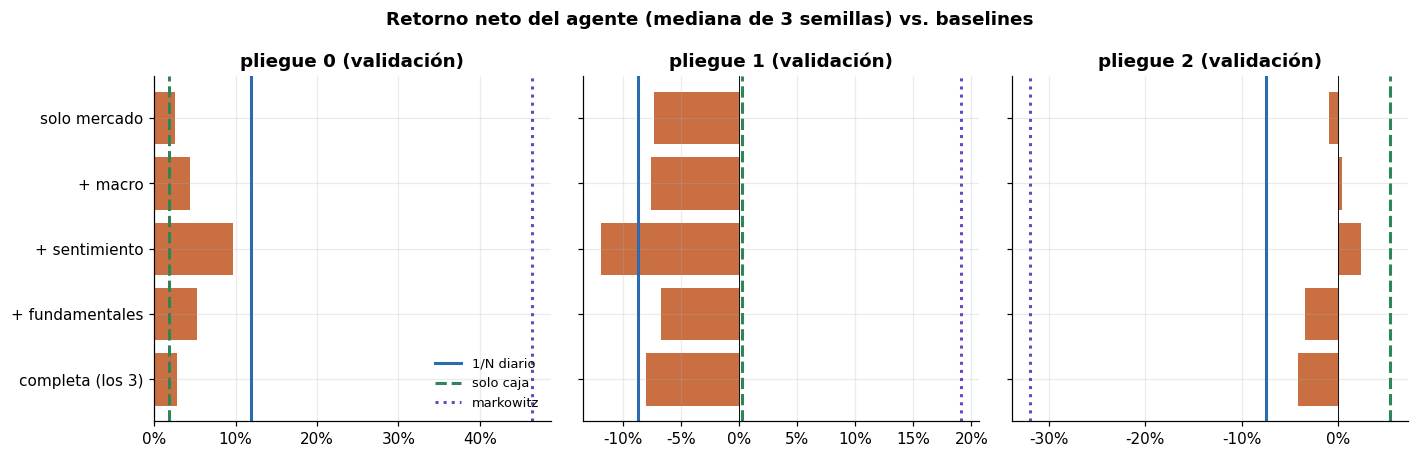

In [3]:
R8 = pd.concat([filas("ablacion_r8.json"), filas("ablacion_r8_completa.json")])
BASE = carga("ablacion_r8.json")["baselines"]
orden = ["solo_mercado", "mercado_macro", "mercado_sentimiento", "mercado_fundamentales", "completa"]
nombre = {"solo_mercado": "solo mercado", "mercado_macro": "+ macro", "mercado_sentimiento": "+ sentimiento",
          "mercado_fundamentales": "+ fundamentales", "completa": "completa (los 3)"}

# Mediana por pliegue (sobre 3 semillas) frente a los baselines
med = R8.groupby(["brazo", "pliegue"])[METRICAS].median().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for k, ax in enumerate(axes):
    m = med[med.pliegue == k].set_index("brazo").loc[orden]
    ax.barh([nombre[b] for b in orden], m["retorno_total"], color=C["agente"], alpha=0.85)
    for bl, c, ls in [("1/N diario", C["1N"], "-"), ("solo caja", C["caja"], "--"), ("markowitz", C["morado"], ":")]:
        ax.axvline(BASE[f"pliegue{k}"][bl]["retorno_total"], color=c, ls=ls, lw=2, label=bl)
    ax.axvline(0, color="k", lw=0.6); ax.xaxis.set_major_formatter(pct)
    ax.set_title(f"pliegue {k} (validación)"); ax.invert_yaxis()
axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Retorno neto del agente (mediana de 3 semillas) vs. baselines", fontweight="bold")
plt.tight_layout(); plt.show()

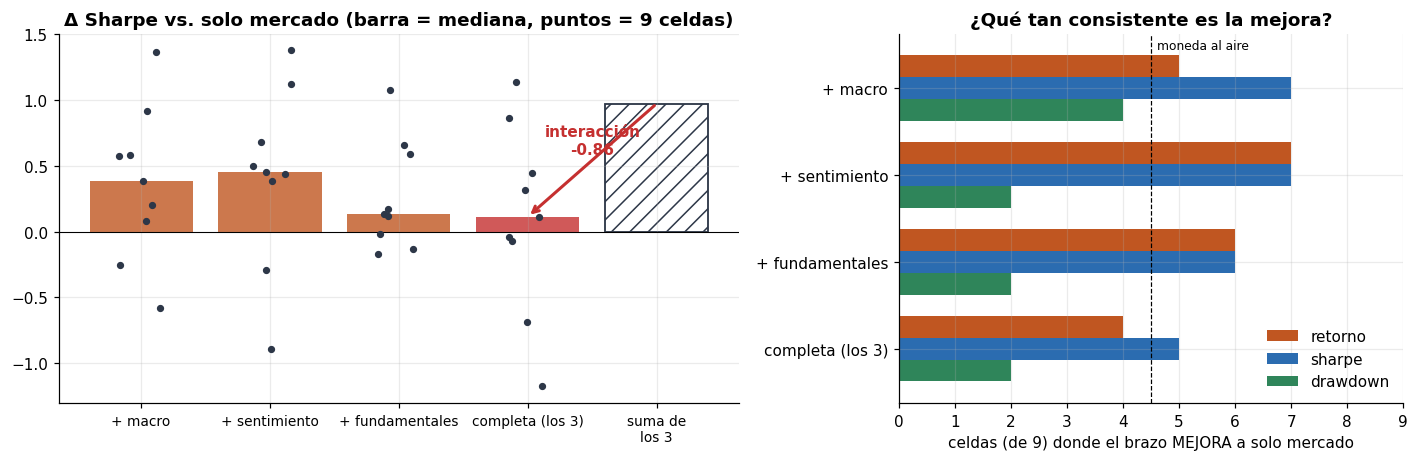

,retorno_total,sharpe,sortino,max_drawdown,rotacion_anual
+ macro,+1.4%,+0.384,+0.415,-1.0%,-0.39
+ sentimiento,+1.8%,+0.452,+0.653,-2.0%,+0.73
+ fundamentales,+0.6%,+0.136,+0.273,-1.6%,-0.36
completa (los 3),-0.1%,+0.113,+0.019,-2.5%,-0.15
suma de los 3 canales,+3.8%,+0.972,+1.341,-4.5%,-0.02
INTERACCIÓN (completa − suma),-3.9%,-0.860,-1.322,+2.0%,-0.13


In [4]:
# Aporte PAREADO de cada canal: brazo − solo_mercado, misma semilla y pliegue
ref = R8[R8.brazo == "solo_mercado"].set_index(["pliegue", "seed"])
dif = {}
for b in orden[1:]:
    x = R8[R8.brazo == b].set_index(["pliegue", "seed"])
    dif[b] = (x[METRICAS] - ref[METRICAS]).reset_index()
# Mediana de las 9 diferencias pareadas: la misma convención que ablacion_r8.py
tab = pd.DataFrame({nombre[b]: d[["retorno_total", "sharpe", "sortino", "max_drawdown", "rotacion_anual"]].median()
                    for b, d in dif.items()}).T
suma = tab.iloc[:3].sum()
tab.loc["suma de los 3 canales"] = suma
tab.loc["INTERACCIÓN (completa − suma)"] = tab.loc["completa (los 3)"] - suma

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
for i, b in enumerate(orden[1:]):
    d = dif[b]["sharpe"]
    ax.bar(i, d.median(), color=C["rojo"] if b == "completa" else C["agente"], alpha=0.8)
    ax.scatter(np.full(len(d), i) + np.random.default_rng(i).uniform(-.18, .18, len(d)), d,
               color=C["oscuro"], s=14, zorder=3)
ax.bar(4, suma["sharpe"], color="none", edgecolor=C["oscuro"], hatch="//", lw=1.2)
ax.set_xticks(range(5), [nombre[b] for b in orden[1:]] + ["suma de\nlos 3"], fontsize=9)
ax.axhline(0, color="k", lw=0.7)
ax.set_title("Δ Sharpe vs. solo mercado (barra = mediana, puntos = 9 celdas)")
ax.annotate("", xy=(3, tab.loc["completa (los 3)", "sharpe"]), xytext=(4, suma["sharpe"]),
            arrowprops=dict(arrowstyle="->", color=C["rojo"], lw=2))
ax.text(3.5, (suma["sharpe"] + tab.loc["completa (los 3)", "sharpe"]) / 2 + .05,
        f"interacción\n{tab.iloc[-1]['sharpe']:+.2f}", color=C["rojo"], ha="center", fontweight="bold")

ax = axes[1]
pos = {b: (dif[b][["retorno_total", "sharpe", "max_drawdown"]] > 0).sum() for b in orden[1:]}
pos = pd.DataFrame(pos).T.rename(columns={"retorno_total": "retorno", "max_drawdown": "drawdown"})
pos.index = [nombre[b] for b in pos.index]
pos.plot.barh(ax=ax, color=[C["agente"], C["1N"], C["caja"]], width=0.75)
ax.axvline(4.5, color="k", ls="--", lw=0.8); ax.text(4.6, -0.45, "moneda al aire", fontsize=8)
ax.set_xlim(0, 9); ax.set_xlabel("celdas (de 9) donde el brazo MEJORA a solo mercado")
ax.set_title("¿Qué tan consistente es la mejora?"); ax.invert_yaxis(); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

display(tab.style.format({"retorno_total": "{:+.1%}", "sharpe": "{:+.3f}", "sortino": "{:+.3f}",
                          "max_drawdown": "{:+.1%}", "rotacion_anual": "{:+.2f}"})
        .set_caption("Aporte pareado vs. solo mercado (mediana de 9 celdas)"))

**Lectura.**
- Cada canal **por separado** sube un poco el Sharpe (+0.14 a +0.45), pero con 3 semillas
  eso es compatible con ruido: mejora en ~5 de 9 celdas, una moneda al aire.
- **Juntos se estorban**: `completa` no llega ni a la cuarta parte de la suma
  (interacción ≈ **−0.86 de Sharpe, −3.9 pp de retorno**). Y empeora el drawdown en 7 de 9.
- **La predicción pre-registrada falló**: se esperaba que `completa` rotara *más*
  (381 dimensiones) y rota *menos*. El deterioro no viene por costos.
- Ninguna vista le gana a la caja de forma sistemática (1 de 3 pliegues). **Ningún canal
  mueve la vara.**

---
## 2 · ¿Por qué entrenar más empeora? (D25)

Con 10 semillas y 1 M de pasos, la **recompensa de entrenamiento sube y se estabiliza**
(la curva de aprendizaje "clásica"), pero el desempeño en validación **baja** a medida que
se entrena más. Es la señal de que el agente optimiza muy bien **algo que no es lo que
queremos**.

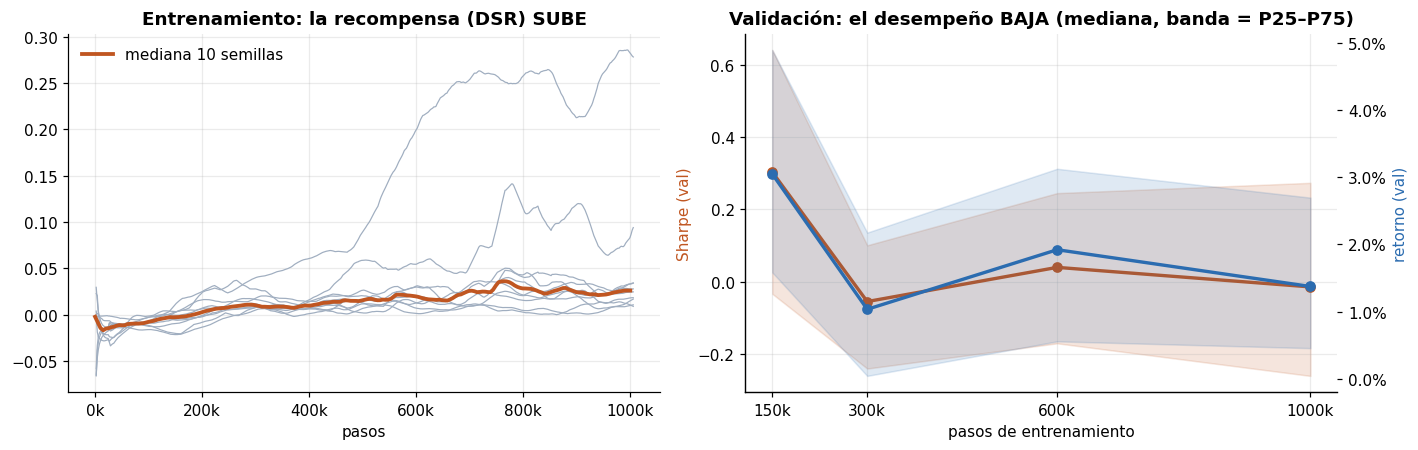

,retorno_total,sharpe,max_drawdown,rotacion_anual
pasos,,,,
150000,3.0%,0.304,-3.5%,1.91
300000,1.0%,-0.055,-5.6%,2.95
600000,1.9%,0.040,-6.0%,4.46
1000000,1.4%,-0.014,-6.4%,5.18


In [5]:
D25 = carga("d25_presupuesto.json"); Z = np.load(ART / "d25_curvas.npz")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
grid = np.linspace(0, 1_000_000, 200); todas = []
for s in range(10):
    x, y = Z[f"s{s}__pasos"], Z[f"s{s}__recompensa_paso"]
    y = pd.Series(y).rolling(max(1, len(y) // 40), min_periods=1).mean().values
    ax.plot(x, y, color=C["gris"], lw=0.8); todas.append(np.interp(grid, x, y))
ax.plot(grid, np.median(todas, axis=0), color=C["agente"], lw=2.5, label="mediana 10 semillas")
ax.set_title("Entrenamiento: la recompensa (DSR) SUBE"); ax.set_xlabel("pasos"); ax.legend()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))

ax = axes[1]
cps = D25["config"]["checkpoints"]
M = pd.DataFrame([{**c, "seed": s} for s, v in D25["semillas"].items() for c in v["checkpoints"]])
for m, c, lab in [("sharpe", C["agente"], "Sharpe (val)"), ("retorno_total", C["1N"], "retorno (val)")]:
    g = M.groupby("pasos")[m]
    ax2 = ax if m == "sharpe" else ax.twinx()
    ax2.plot(cps, g.median(), "o-", color=c, lw=2.2, label=lab)
    ax2.fill_between(cps, g.quantile(.25), g.quantile(.75), color=c, alpha=.15)
    ax2.set_ylabel(lab, color=c)
    if m == "retorno_total": ax2.yaxis.set_major_formatter(pct1); ax2.grid(False)
ax.set_title("Validación: el desempeño BAJA (mediana, banda = P25–P75)")
ax.set_xticks(cps, [f"{c//1000}k" for c in cps]); ax.set_xlabel("pasos de entrenamiento")
plt.tight_layout(); plt.show()
display(M.groupby("pasos")[["retorno_total", "sharpe", "max_drawdown", "rotacion_anual"]].median()
        .style.format({"retorno_total": "{:.1%}", "sharpe": "{:.3f}", "max_drawdown": "{:.1%}", "rotacion_anual": "{:.2f}"})
        .set_caption("Pliegue 0, mediana de 10 semillas por checkpoint"))

**La causa, medida (§7.11).** El DSR reordenado es `r ∝ (R−A) − (A/2B)·(R²−B)`: el
"precio" de la varianza es proporcional al retorno medio reciente. Cuando el mercado es
**plano** (2013-2018, el tramo de entrenamiento) ese precio oscila de signo:

- en **44% de los días** de entrenamiento el DSR **paga** por volatilidad en vez de castigarla;
- el término de riesgo pesa solo 7-10% de la señal: el DSR es ~90% retorno puro;
- **no ordena**: su correlación de rangos con el Sharpe, sobre 18 estrategias reales, es
  **ρ = +0.11** en entrenamiento. Le paga **5.7× más a Markowitz (que pierde) que al 1/N (que gana)**.

⇒ El agente no está "mal entrenado": aprende fielmente una recompensa que, en ese
tramo, **no premia lo que el Sharpe premia**.

---
## 3 · El tamiz: elegir la recompensa **sin entrenar** (D4)

Entrenar cuesta corridas del contador de configuraciones (que penaliza el Sharpe
deflactado). El tamiz evalúa cada recompensa candidata sobre **18 estrategias reales**
(1/N, Markowitz, momentum…) en train y val, **sin agente**, con 4 criterios pre-registrados:

| criterio | pregunta | umbral |
|---|---|---|
| **T1 orden** | ¿ordena las estrategias como el Sharpe? | ρ ≥ 0.50 en train **y** val |
| **T2 ruido** | ¿paga por agregar volatilidad pura? | en ninguna estrategia |
| **T3 riesgo** | ¿el término de riesgo pesa en la señal? | ≥ 20% |
| **T4 peaje** | ¿baja cuando sube el costo? | ≥ 1% por pb, monótona |

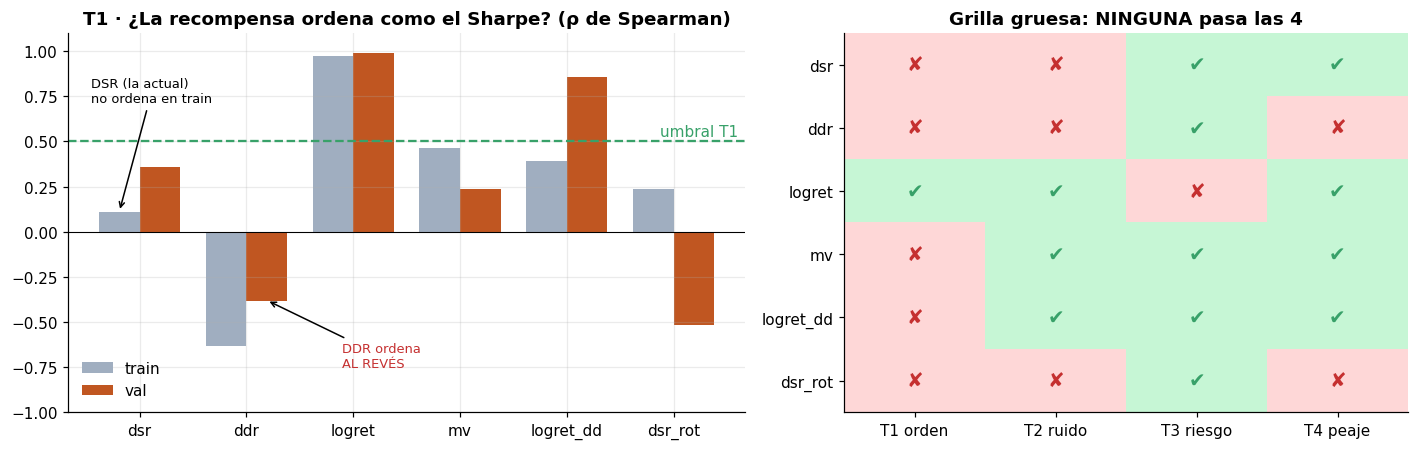

In [6]:
TZ = carga("d4_tamiz_recompensas.json")["resultados"]
cand = ["dsr", "ddr", "logret", "mv", "logret_dd", "dsr_rot"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]; x = np.arange(len(cand)); w = .38
ax.bar(x - w/2, [TZ[c]["rho_sharpe_train"] for c in cand], w, color=C["gris"], label="train")
ax.bar(x + w/2, [TZ[c]["rho_sharpe_val"] for c in cand], w, color=C["agente"], label="val")
ax.axhline(.5, color=C["ok"], ls="--", lw=1.5); ax.text(5.6, .53, "umbral T1", color=C["ok"], ha="right")
ax.axhline(0, color="k", lw=.7); ax.set_xticks(x, cand); ax.set_ylim(-1, 1.1)
ax.set_title("T1 · ¿La recompensa ordena como el Sharpe? (ρ de Spearman)"); ax.legend(loc="lower left")
ax.annotate("DSR (la actual)\nno ordena en train", xy=(0 - w/2, .11), xytext=(-0.45, .72),
            arrowprops=dict(arrowstyle="->"), fontsize=8.5)
ax.annotate("DDR ordena\nAL REVÉS", xy=(1 + w/2, -.38), xytext=(1.9, -.75),
            arrowprops=dict(arrowstyle="->"), fontsize=8.5, color=C["rojo"])

ax = axes[1]
crit = ["PASA_T1", "PASA_T2", "PASA_T3", "PASA_T4"]
mat = np.array([[TZ[c][k] for k in crit] for c in cand], dtype=float)
ax.imshow(mat, cmap=plt.matplotlib.colors.ListedColormap(["#fed7d7", "#c6f6d5"]), aspect="auto")
for i in range(len(cand)):
    for j in range(4):
        ax.text(j, i, "✔" if mat[i, j] else "✘", ha="center", va="center", fontsize=13,
                color=C["ok"] if mat[i, j] else C["rojo"])
ax.set_xticks(range(4), ["T1 orden", "T2 ruido", "T3 riesgo", "T4 peaje"]); ax.set_yticks(range(len(cand)), cand)
ax.grid(False); ax.set_title("Grilla gruesa: NINGUNA pasa las 4")
plt.tight_layout(); plt.show()

**Lo que el tamiz dejó firme:**
- **La DDR (candidata V1 de D4) no debe correrse**: ordena al revés, paga por ruido en 83%
  de las estrategias y un costo mayor le *sube* la recompensa. Ahorra 30 corridas.
- `logret` ordena perfecto pero no ve el riesgo (T3 = 0%); `dsr_rot` se vuelve ciego al costo.

### 3b · El barrido fino de λ (26-sep) — **corrigió una conclusión**

La grilla gruesa saltaba de λ=0.51 a λ=1.02, y el cruce entre T1 y T3 caía justo en ese
hueco. Se escribió "no existe λ que cumpla ambos"; **era falso**. El barrido fino
(paso 0.025, los 3 pliegues, sin entrenar) lo muestra:

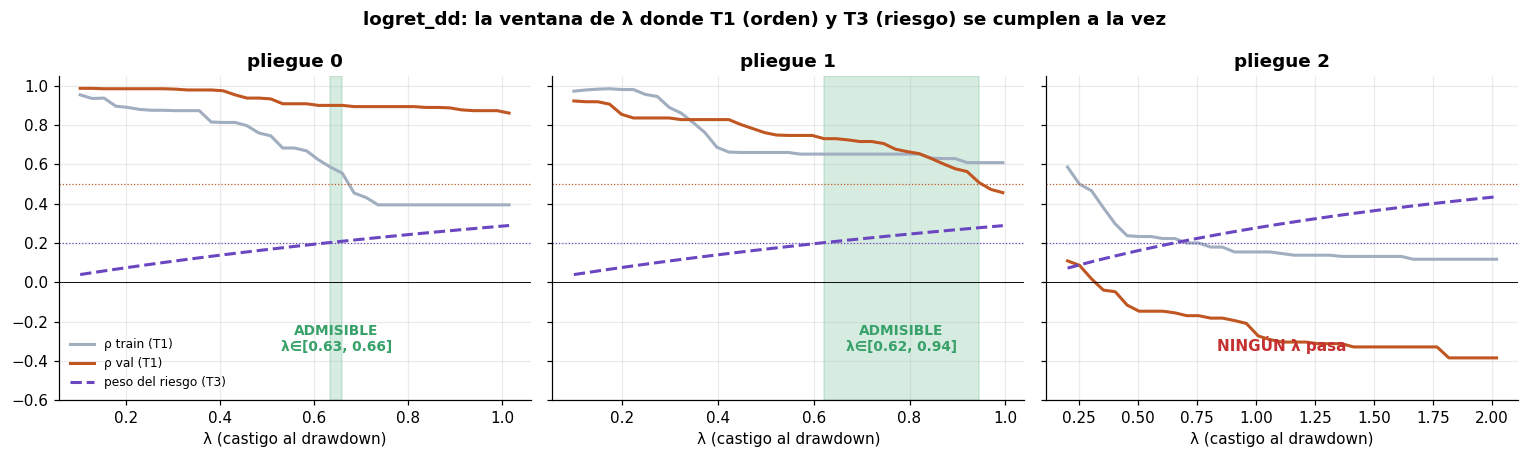

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for k, ax in enumerate(axes):
    F = pd.DataFrame(carga(f"d4_tamiz_barrido_fino_p{k}.json")["frontera"]["logret_dd"])
    ok = F.PASA_T1 & F.PASA_T3
    ax.plot(F.lam, F.rho_sharpe_train, color=C["gris"], lw=2, label="ρ train (T1)")
    ax.plot(F.lam, F.rho_sharpe_val, color=C["agente"], lw=2, label="ρ val (T1)")
    ax.plot(F.lam, F.peso_riesgo, color=C["morado"], lw=2, ls="--", label="peso del riesgo (T3)")
    ax.axhline(.5, color=C["agente"], lw=.8, ls=":"); ax.axhline(.2, color=C["morado"], lw=.8, ls=":")
    if ok.any():
        ax.axvspan(F.lam[ok].min(), F.lam[ok].max(), color=C["ok"], alpha=.2)
        ax.text(F.lam[ok].mean(), -.35, f"ADMISIBLE\nλ∈[{F.lam[ok].min():.2f}, {F.lam[ok].max():.2f}]",
                ha="center", color=C["ok"], fontweight="bold", fontsize=9)
    else:
        ax.text(F.lam.mean(), -.35, "NINGÚN λ pasa", ha="center", color=C["rojo"], fontweight="bold")
    ax.axhline(0, color="k", lw=.6); ax.set_xlabel("λ (castigo al drawdown)")
    ax.set_title(f"pliegue {k}")
axes[0].legend(fontsize=8, loc="lower left"); axes[0].set_ylim(-.6, 1.05)
fig.suptitle("logret_dd: la ventana de λ donde T1 (orden) y T3 (riesgo) se cumplen a la vez", fontweight="bold")
plt.tight_layout(); plt.show()

- **Pliegue 0** (donde se pre-registró el tamiz): ventana **angosta**, λ ≈ 0.63–0.68 (medida en paso 0.01; la figura usa 0.025), y ahí
  pasa también T2 y T4 → **es una recompensa admisible**.
- **Pliegue 1**: ventana ancha (≈ 0.65–0.95).
- **Pliegue 2**: **ninguna** — ρ en val nunca llega a 0.50 (hipótesis: en ese año el exceso
  es negativo y el Sharpe premia la volatilidad).

⇒ La ventana común a los pliegues 0 y 1 es λ ≈ 0.65–0.68, y el pliegue 2 no admite ninguno.
Es una **opción nueva (a′) para D4**, pero con salvedades: se elige λ *después* de ver el
tamiz y no es estable. **Decisión del autor pendiente.**

### 3c · ¿El tamiz predice el desempeño del agente? — **No**

Antes del barrido fino se entrenaron dos brazos (18 corridas) con las λ de la grilla gruesa:

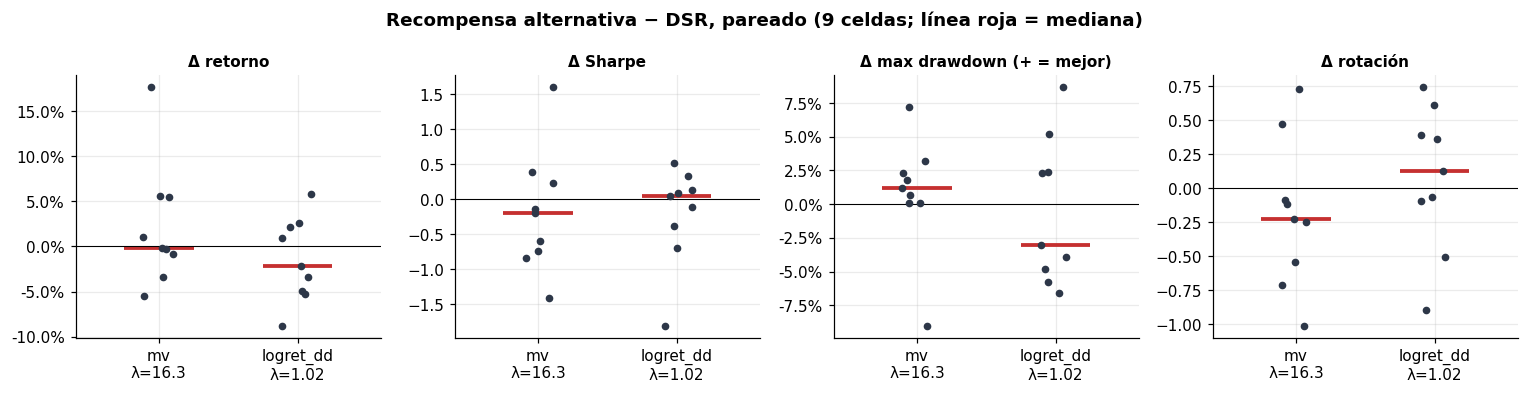

In [8]:
base = filas("ablacion_r8.json").query("brazo == 'solo_mercado'").set_index(["pliegue", "seed"])
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for j, (m, lab, fmt) in enumerate([("retorno_total", "Δ retorno", pct1), ("sharpe", "Δ Sharpe", None),
                                   ("max_drawdown", "Δ max drawdown (+ = mejor)", pct1),
                                   ("rotacion_anual", "Δ rotación", None)]):
    ax = axes[j]
    for i, (f, lab_b) in enumerate([("ablacion_d4_mv.json", "mv\nλ=16.3"),
                                    ("ablacion_d4_logret_dd.json", "logret_dd\nλ=1.02")]):
        d = (filas(f).set_index(["pliegue", "seed"])[m] - base[m]).dropna()
        ax.scatter(np.full(len(d), i) + np.random.default_rng(j).uniform(-.12, .12, len(d)), d,
                   color=C["oscuro"], s=16, zorder=3)
        ax.hlines(d.median(), i - .25, i + .25, color=C["rojo"], lw=2.5)
    ax.axhline(0, color="k", lw=.7); ax.set_xticks([0, 1], ["mv\nλ=16.3", "logret_dd\nλ=1.02"])
    ax.set_xlim(-.6, 1.6); ax.set_title(lab, fontsize=10)
    if fmt: ax.yaxis.set_major_formatter(fmt)
fig.suptitle("Recompensa alternativa − DSR, pareado (9 celdas; línea roja = mediana)", fontweight="bold")
plt.tight_layout(); plt.show()

- `logret_dd` iba a **rotar menos y caer menos**; rota **más** y su drawdown sale **peor**
  (−3 pp). Las dos condiciones de falsación se cumplieron → **el tamiz no predice**.
- Cambiar la recompensa **no mueve la vara**: le ganan a la caja DSR 1/3 · mv 0/3 · logret_dd 0/3.
- El tamiz **sobrevive como caracterización** (sirve para *descartar* una recompensa rota,
  como la DDR), no para *elegir* entre sanas.

> **Síntesis de OE1 hasta hoy — las tres vías de mejora, las tres medidas, las tres negativas:**
> más cómputo → empeora (§2) · otra recompensa → da lo mismo (§3) · más señales → se estorban (§1).
> Lo consistente es que **falta señal explotable o el costo se la come**, igual que le pasa
> a Markowitz. Eso deja de ser un defecto del método y pasa a ser **resultado de la tesis**.

---
## 4 · R7 multi-algoritmo: PPO + SAC + DDPG

El documento de tesis compromete **tres** algoritmos y las 134 corridas eran todas PPO
(inconsistencia #2). Esta semana:
- `src/agents/algoritmos.py`: una **fábrica única**; SAC y DDPG comparten el mismo espacio
  de acción que PPO (biyección `artanh`), así las comparaciones son justas. La configuración
  de PPO conserva **el mismo hash** del registro (hay un test contra el registro real).
- **Calibración de la exploración sin tocar validación**: se busca el σ / `ent_coef` cuyo
  *peaje de ruido* (rotación estocástica − determinista, sobre train) iguale al de PPO.

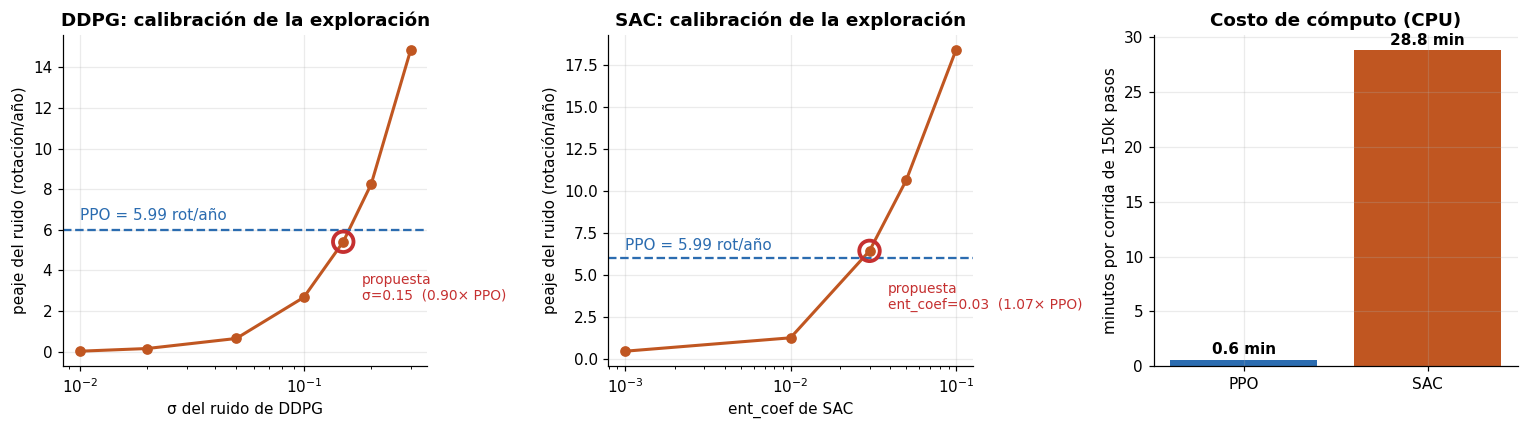

In [9]:
E, EF = carga("exploracion_r7.json"), carga("exploracion_r7_fino.json")
ref = E["ppo_log_std_-2"]["estocastica"]
dd = {float(s): v - E["ddpg"]["determinista"] for s, v in {**E["ddpg"]["por_sigma"], **EF["ddpg"]["por_sigma"]}.items()}
sac = {float(k): v["estocastica"] - v["determinista"]
       for k, v in {**E["sac"]["por_ent_coef"], **EF["sac"]["por_ent_coef"]}.items()}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, dat, xl, elegido, t in [(axes[0], dd, "σ del ruido de DDPG", 0.15, "DDPG"),
                                (axes[1], sac, "ent_coef de SAC", 0.03, "SAC")]:
    xs = sorted(dat); ax.plot(xs, [dat[x] for x in xs], "o-", color=C["agente"], lw=2)
    ax.axhline(ref, color=C["1N"], ls="--"); ax.text(xs[0], ref * 1.08, f"PPO = {ref:.2f} rot/año", color=C["1N"])
    ax.scatter([elegido], [dat[elegido]], s=180, facecolor="none", edgecolor=C["rojo"], lw=2.5, zorder=4)
    ax.annotate(f"propuesta\n{xl.split()[0]}={elegido}  ({dat[elegido]/ref:.2f}× PPO)", (elegido, dat[elegido]),
                xytext=(12, -38), textcoords="offset points", color=C["rojo"], fontsize=9)
    ax.set_xscale("log"); ax.set_xlabel(xl); ax.set_ylabel("peaje del ruido (rotación/año)")
    ax.set_title(f"{t}: calibración de la exploración")
ax = axes[2]
vel = {"PPO": 0.6 * 60 / 150, "SAC": EF["sac"]["por_ent_coef"]["0.03"]["ms_por_paso"]}
ax.bar(["PPO", "SAC"], [0.6, EF["sac"]["por_ent_coef"]["0.03"]["ms_por_paso"] * 150_000 / 60_000],
       color=[C["1N"], C["agente"]])
ax.set_ylabel("minutos por corrida de 150k pasos"); ax.set_title("Costo de cómputo (CPU)")
for i, v in enumerate([0.6, EF["sac"]["por_ent_coef"]["0.03"]["ms_por_paso"] * 2.5]):
    ax.text(i, v + .5, f"{v:.1f} min", ha="center", fontweight="bold")
plt.tight_layout(); plt.show()

- **Propuesta**: DDPG σ = 0.15 (0.90× el peaje de PPO) · SAC `ent_coef` = 0.03 (1.07×).
  **Falta que el autor la fije en D3** antes de correr.
- Alerta: SAC **determinista** ya rota ~22 veces/año a 20 k pasos (PPO: 0) — el mismo
  síntoma de sobre-rotación que D22 vio en PPO al principio.
- SAC es **~50× más lento** que PPO en CPU (~29 min por corrida) → 9 celdas ≈ 4.5 h.

---
## 5 · Enlace con Bloomberg

**Regla del acta (§E):** Bloomberg es capa de **validación y enriquecimiento**, con volcado
único a archivo fechado — **nunca** una dependencia viva. El cierre autoritativo sigue
siendo la BVL.

| pieza | estado | para qué sirve |
|---|---|---|
| P0 · puntas, volumen, OHLC, flotante 2011-2026 | ✅ bajado (05-sep) | serie **histórica** de spreads → costos |
| Validación del panel (7/7 activos) | ✅ | detectó y corrigió el desfase de fechas de la BVL |
| **A1 · fechas de anuncio (EVTS)** | ✅ **cerrado 19-sep** | fundamentales *point-in-time*; eventos para R5 |
| **LQA · costo de liquidación** | ✅ **cerrado 26-sep** | validar el modelo de costos |
| A2 · fundamentales OR/MR con `Dts=S` | ⛔ bloqueado (Excel da `#N/A Review` en todo) | ticket abierto (BHRQ) |
| A3 · índice local de retorno total | ⏳ pendiente | *baseline* de mercado de D10 |

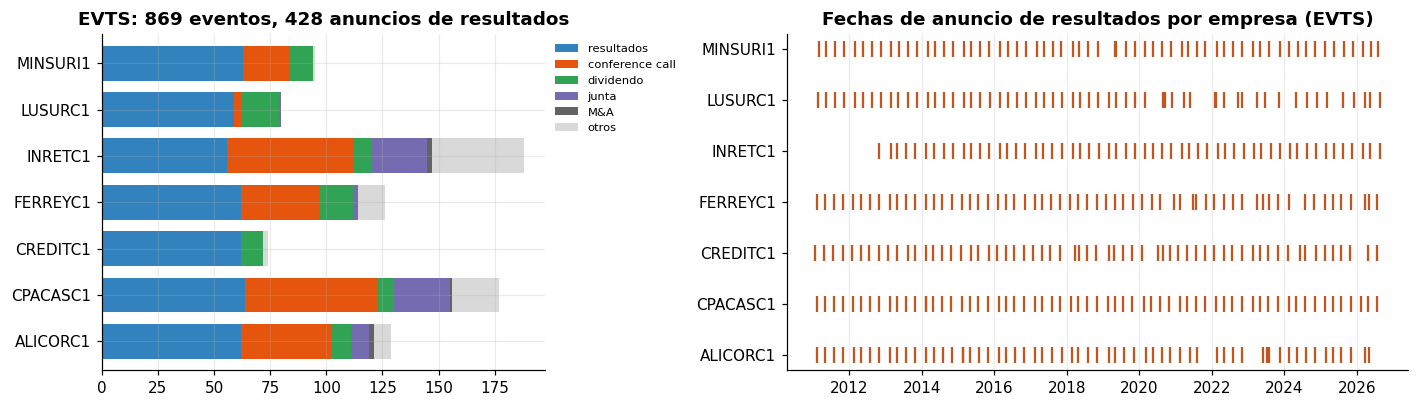

In [10]:
import openpyxl
wb = openpyxl.load_workbook(BBG / "ern_evts_20260919.xlsx", read_only=True, data_only=True)
ev = []
for ws in wb.worksheets:
    if not ws.title.startswith("EVTS_"): continue
    rows = list(ws.iter_rows(values_only=True))
    hdr = rows[0]; i_f, i_t = hdr.index("Fecha"), hdr.index("Tipo de evento")
    for r in rows[1:]:
        if r[i_t] and isinstance(r[i_f], (pd.Timestamp, __import__("datetime").datetime)):
            ev.append({"ticker": ws.title[5:].replace("CPACASI1", "CPACASC1"), "fecha": r[i_f], "tipo": r[i_t]})
EV = pd.DataFrame(ev)
tipos = {"ER": "resultados", "EC": "conference call", "DV": "dividendo", "SM": "junta", "CP": "otros", "MA": "M&A"}
EV["tipo_n"] = EV.tipo.map(tipos).fillna("otros")
tab_ev = EV.pivot_table(index="ticker", columns="tipo_n", values="fecha", aggfunc="count", fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
tab_ev[[c for c in ["resultados", "conference call", "dividendo", "junta", "M&A", "otros"] if c in tab_ev]] \
    .plot.barh(stacked=True, ax=axes[0], colormap="tab20c", width=.75)
axes[0].set_ylabel("")
axes[0].set_title(f"EVTS: {len(EV)} eventos, {int((EV.tipo=='ER').sum())} anuncios de resultados")
axes[0].legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
er = EV[EV.tipo == "ER"]
for i, t in enumerate(sorted(er.ticker.unique())):
    f = er[er.ticker == t].fecha
    axes[1].scatter(f, np.full(len(f), i), marker="|", s=120, color=C["agente"])
axes[1].set_yticks(range(er.ticker.nunique()), sorted(er.ticker.unique()))
axes[1].set_title("Fechas de anuncio de resultados por empresa (EVTS)"); axes[1].grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()

**A1.** Las fechas **sí** se usan para confirmar que el anuncio ocurrió (62-96% coinciden a
≤1 día con el `registerDate` de la BVL). Las **horas no se usan**: se midieron tres regímenes
(relleno 2011-16, hora de Lima 2018-20, hora de *captura* de Bloomberg 2021-25, que corre la
fecha 1-2 días). El `known_date` se queda con la BVL.

### 5b · El hallazgo de la semana: el spread **no es constante**

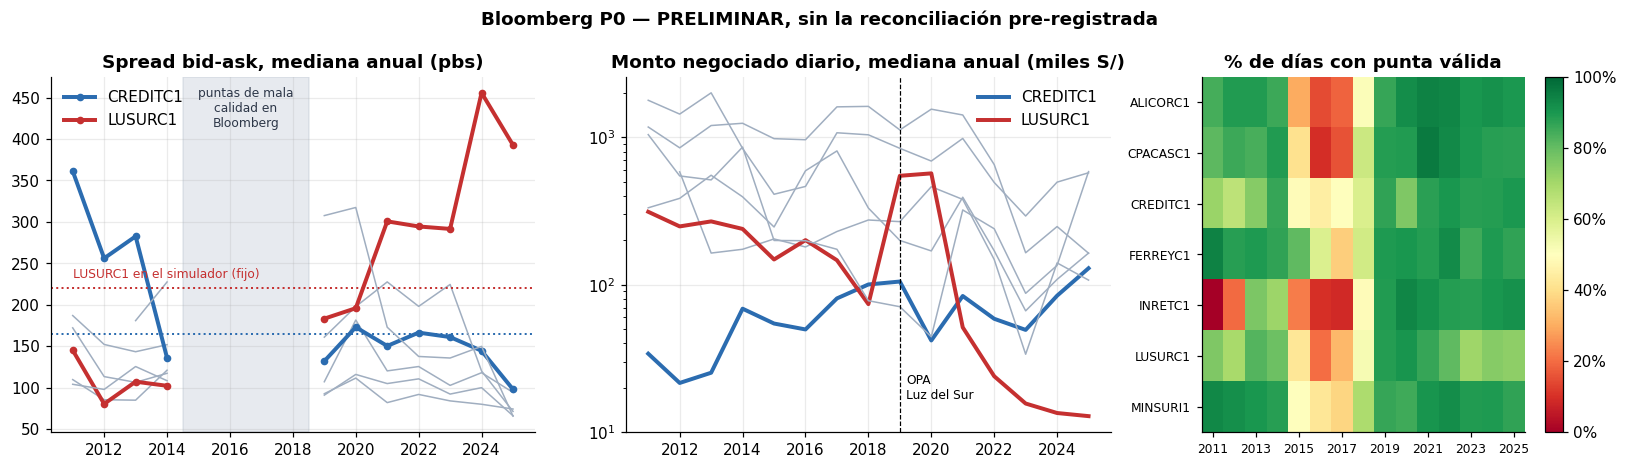

0,2012,2014,2019,2022,2025
ALICORC1,114,118,93,92,75
CPACASC1,152,152,107,126,95
CREDITC1,256,136,132,167,98
FERREYC1,86,121,91,111,66
INRETC1,,228,161,198,72
LUSURC1,81,103,183,295,393
MINSURI1,98,109,308,138,66


In [11]:
raw = pd.read_excel(BBG / "grid_ul1wocu2.xlsx", sheet_name="BASE", header=None)
tick = raw.iloc[0].ffill().str.replace(" PE Equity", "", regex=False)
campo = raw.iloc[2]
fechas = pd.to_datetime(raw.iloc[3:, 0].astype(float), unit="D", origin="1899-12-30")
def serie(t, f):
    j = [k for k in range(1, raw.shape[1]) if tick[k] == t and campo[k] == f][0]
    return pd.to_numeric(raw.iloc[3:, j], errors="coerce").set_axis(fechas)
SP, MONTO, FRESCO = {}, {}, {}
for t in sorted(tick.dropna().unique()):
    b, a, v = serie(t, "PX_BID"), serie(t, "PX_ASK"), serie(t, "PX_VOLUME")
    fresca = (b.diff() != 0) | (a.diff() != 0)       # la punta cambió respecto del día anterior
    ok = (b > 0) & (a > b) & (v > 0) & fresca        # fuera: sin negociación, cruzadas o congeladas
    SP[t] = ((a - b) / ((a + b) / 2) * 1e4)[ok]
    MONTO[t] = serie(t, "TURNOVER")[v > 0]
    FRESCO[t] = ok.groupby(ok.index.year).mean()
FRESCO = pd.DataFrame(FRESCO).loc[2011:2025]
anual = pd.DataFrame({t: s.groupby(s.index.year).median() for t, s in SP.items()}).loc[2011:2025]
anual = anual.where(FRESCO >= 0.6)                  # años con <60% de puntas válidas: no se leen
anual.loc[2015:2018] = np.nan                         # tramo con puntas congeladas en casi todos
monto = pd.DataFrame({t: s.groupby(s.index.year).median() for t, s in MONTO.items()}).loc[2011:2025]
snap = carga("costos.json")["spread_snapshot_ida_vuelta_bps"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
for t in anual:
    hl = t in ("LUSURC1", "CREDITC1")
    kw = dict(lw=2.6, color=C["rojo"] if t == "LUSURC1" else C["1N"]) if hl else dict(lw=1, color=C["gris"])
    axes[0].plot(anual.index, anual[t], "o-" if hl else "-", ms=4, label=t if hl else None, **kw)
    axes[1].plot(monto.index, monto[t] / 1e3, label=t if hl else None, **kw)
    if hl: axes[0].axhline(snap[t], color=kw["color"], ls=":", lw=1.3)
axes[0].axvspan(2014.5, 2018.5, color=C["gris"], alpha=.25)
axes[0].text(2016.5, 0.97, "puntas de mala\ncalidad en\nBloomberg", ha="center", va="top", fontsize=8,
             color=C["oscuro"], transform=axes[0].get_xaxis_transform())
axes[0].text(2011, snap["LUSURC1"] + 12, "LUSURC1 en el simulador (fijo)", color=C["rojo"], fontsize=8)
axes[0].set_title("Spread bid-ask, mediana anual (pbs)"); axes[0].legend(loc="upper left")
axes[1].set_yscale("log"); axes[1].set_title("Monto negociado diario, mediana anual (miles S/)")
axes[1].legend(); axes[1].axvline(2019, color="k", ls="--", lw=.8)
axes[1].text(2019.2, monto.min().min() / 1e3 * 1.3, "OPA\nLuz del Sur", fontsize=8)
im = axes[2].imshow(FRESCO.T.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
axes[2].set_yticks(range(FRESCO.shape[1]), FRESCO.columns, fontsize=8)
axes[2].set_xticks(range(0, 15, 2), FRESCO.index[::2], fontsize=8); axes[2].grid(False)
axes[2].set_title("% de días con punta válida"); plt.colorbar(im, ax=axes[2], format=pct)
fig.suptitle("Bloomberg P0 — PRELIMINAR, sin la reconciliación pre-registrada", fontweight="bold")
plt.tight_layout(); plt.show()
display(anual.loc[[2012, 2014, 2019, 2022, 2025]].round(0).astype("Int64").T
        .style.set_caption("Spread mediano (pbs) — años de puntas válidas"))

- **Luz del Sur "se muere" tras la OPA de 2019**: el monto diario cae de ~S/250 k a ~S/14 k y
  el spread se multiplica. **CREDITC1 va al revés**: hoy es la más líquida.
- El simulador usa **un spread fijo (foto del 27-jul-2026)** para toda la historia, e
  **impacto de mercado = 0**. LUSURC1 pasa de ~100 pbs (2012-14) a ~300-400 (2021-25):
  el simulador le cobra de menos en el pasado y CREDITC1, de más.
- **Calidad**: en 2015-2018 las puntas de Bloomberg están congeladas o cruzadas en la mitad
  de los días o más. Por eso la **reconciliación pre-registrada** contra la BVL es obligatoria
  antes de enganchar la serie al simulador — es la primera tarea de §6.

### 5c · LQA: ¿cuánto cuesta liquidar una posición en un día?

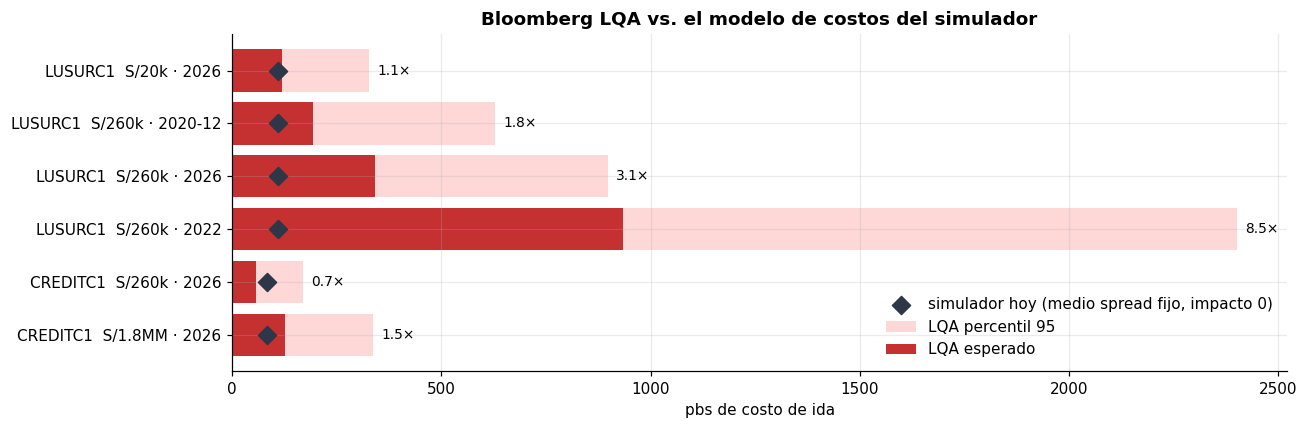

In [12]:
# Capturas LQA del 26-sep (data/raw/bloomberg; confianza 95%, horizonte 1 día).
# Costo LQA = desviación vs. precio medio, SIN comisión -> se compara con el MEDIO spread.
lqa = pd.DataFrame([
    ("LUSURC1", "S/20k · 2026",     118.6,  327.2),
    ("LUSURC1", "S/260k · 2020-12", 193.6,  628.4),
    ("LUSURC1", "S/260k · 2026",    340.3,  897.1),
    ("LUSURC1", "S/260k · 2022",    934.8, 2400.2),
    ("CREDITC1", "S/260k · 2026",    57.6,  168.2),
    ("CREDITC1", "S/1.8MM · 2026",  125.0,  337.6),
], columns=["activo", "orden", "costo_esperado", "costo_p95"])
lqa["simulador"] = lqa.activo.map(lambda t: snap[t] / 2)
fig, ax = plt.subplots(figsize=(12, 4))
y = np.arange(len(lqa))
ax.barh(y, lqa.costo_p95, color="#fed7d7", label="LQA percentil 95")
ax.barh(y, lqa.costo_esperado, color=C["rojo"], label="LQA esperado")
ax.scatter(lqa.simulador, y, marker="D", s=70, color=C["oscuro"], zorder=4, label="simulador hoy (medio spread fijo, impacto 0)")
ax.set_yticks(y, lqa.activo + "  " + lqa.orden); ax.invert_yaxis()
ax.set_xlabel("pbs de costo de ida"); ax.legend(loc="lower right")
ax.set_title("Bloomberg LQA vs. el modelo de costos del simulador")
for i, r in lqa.iterrows(): ax.text(r.costo_p95 + 20, i, f"{r.costo_esperado/r.simulador:.1f}×", va="center", fontsize=9)
plt.tight_layout(); plt.show()

- Para una **orden chica** (S/20 k de LUSURC1) LQA y el simulador **coinciden** (119 vs 110 pbs):
  la foto del spread está bien medida.
- Para el **tamaño real de la cartera** (1/7 de S/1.8 MM ≈ S/260 k) el costo **crece con el
  tamaño y con el año**: hasta **~8×** lo que cobra el simulador en LUSURC1-2022. Falta un
  **término de impacto** ∝ σ·√(Q/ADV).
- Dato que dimensiona: el 18-sep Luz del Sur negoció **S/13,830 en todo el día**; la posición
  1/7 de la cartera equivale a **18 días** de volumen. El flotante del BCP que cita la tesis
  (2.66%) es de 2011: hoy es 2.26%.

---
## 6 · Próximos pasos

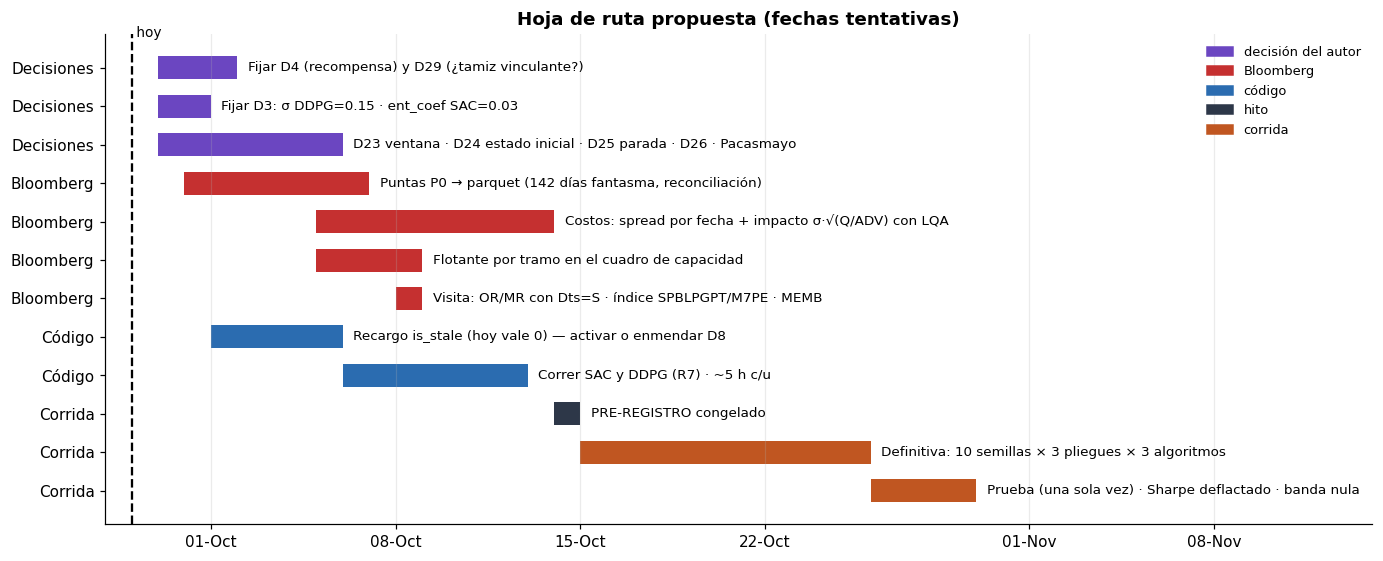

In [13]:
pasos = [
    # (bloque, tarea, inicio, fin, tipo)
    ("Decisiones", "Fijar D4 (recompensa) y D29 (¿tamiz vinculante?)",          "2026-09-29", "2026-10-02", "decision"),
    ("Decisiones", "Fijar D3: σ DDPG=0.15 · ent_coef SAC=0.03",                "2026-09-29", "2026-10-01", "decision"),
    ("Decisiones", "D23 ventana · D24 estado inicial · D25 parada · D26 · Pacasmayo", "2026-09-29", "2026-10-06", "decision"),
    ("Bloomberg",  "Puntas P0 → parquet (142 días fantasma, reconciliación)",   "2026-09-30", "2026-10-07", "bbg"),
    ("Bloomberg",  "Costos: spread por fecha + impacto σ·√(Q/ADV) con LQA",      "2026-10-05", "2026-10-14", "bbg"),
    ("Bloomberg",  "Flotante por tramo en el cuadro de capacidad",               "2026-10-05", "2026-10-09", "bbg"),
    ("Bloomberg",  "Visita: OR/MR con Dts=S · índice SPBLPGPT/M7PE · MEMB",      "2026-10-08", "2026-10-09", "bbg"),
    ("Código",     "Recargo is_stale (hoy vale 0) — activar o enmendar D8",      "2026-10-01", "2026-10-06", "code"),
    ("Código",     "Correr SAC y DDPG (R7) · ~5 h c/u",                          "2026-10-06", "2026-10-13", "code"),
    ("Corrida",    "PRE-REGISTRO congelado",                                      "2026-10-14", "2026-10-15", "hito"),
    ("Corrida",    "Definitiva: 10 semillas × 3 pliegues × 3 algoritmos",         "2026-10-15", "2026-10-26", "run"),
    ("Corrida",    "Prueba (una sola vez) · Sharpe deflactado · banda nula",      "2026-10-26", "2026-10-30", "run"),
]
col_t = {"decision": C["morado"], "bbg": C["rojo"], "code": C["1N"], "hito": C["oscuro"], "run": C["agente"]}
fig, ax = plt.subplots(figsize=(13, 5.2))
for i, (b, t, a, z, k) in enumerate(pasos):
    a, z = pd.Timestamp(a), pd.Timestamp(z)
    ax.barh(i, max((z - a).days, 1), left=a, color=col_t[k], height=.6)
    ax.text(z + pd.Timedelta(days=.4), i, t, va="center", fontsize=8.8)
ax.set_yticks(range(len(pasos)), [p[0] for p in pasos]); ax.invert_yaxis()
ax.axvline(pd.Timestamp("2026-09-28"), color="k", ls="--"); ax.text(pd.Timestamp("2026-09-28"), -.8, " hoy", fontsize=9)
ax.set_xlim(pd.Timestamp("2026-09-27"), pd.Timestamp("2026-11-14"))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d-%b")); ax.grid(axis="y", alpha=0)
ax.set_title("Hoja de ruta propuesta (fechas tentativas)")
ax.legend(handles=[Patch(color=v, label=k) for k, v in
                   {"decisión del autor": C["morado"], "Bloomberg": C["rojo"], "código": C["1N"],
                    "hito": C["oscuro"], "corrida": C["agente"]}.items()], loc="upper right", fontsize=8.5)
plt.tight_layout(); plt.show()

### 6.1 · Decisiones que bloquean la corrida definitiva (no requieren cómputo)

| | decisión | propuesta / estado |
|---|---|---|
| **D4** | qué recompensa | (c) quedarse con **DSR** y reportar el tamiz como resultado negativo, **o** (a′) `logret_dd` λ≈0.65 con sus salvedades |
| **D29** | ¿el tamiz es vinculante? | propuesta: **solo caracteriza** (descarta rotas, no elige) |
| **D3** | exploración SAC/DDPG | σ = 0.15 · `ent_coef` = 0.03 (calibrado) |
| **D25** | presupuesto de pasos | meseta 750 k vs. fuera de muestra 150 k → pre-registrar parada por rotación |
| **D23 / D24 / D26** | ventana · estado inicial · Markowitz | *expanding* · por decidir · por decidir |
| **Pacasmayo** | salto de +61% el 17-dic-2025 (cae en prueba) | decidir **antes** de mirar ese tramo |

### 6.2 · Bloomberg → modelo de costos (el enganche concreto)

1. **Serie histórica de puntas** (P0, ya bajada) → parquet, limpiando los 142 días de relleno
   y reconciliando contra el snapshot BVL del 27-jul. `half_spread_bps` ya acepta una matriz
   (fecha × activo): el cambio en el entorno es de un argumento.
2. **Término de impacto** `k·σ·√(Q/ADV)`, calibrado con los 6 puntos LQA (2020, 2022, 2026).
3. **Flotante por tramo** (no fijo) en el cuadro de capacidad; LUSURC1 cae de 26% a 2.9%.
4. **Próxima visita al terminal**: par OR/MR con `Dts=S` (si se resuelve el `#N/A Review`),
   índice `SPBLPGPT` / `M7PE` de retorno total (el *baseline* de mercado de D10) y `MEMB`
   sobre `MXPE Index`.

### 6.3 · Preguntas para el asesor

1. ¿Es defendible cerrar D4 con el **DSR** y presentar el tamiz como **resultado negativo**,
   o conviene la opción (a′) aunque λ se elija después de ver?
2. Con el costo de impacto incluido, lo más probable es que el agente **empeore**. ¿Se
   reporta como el resultado central ("falta señal o el costo se la come")?
3. ¿SAC y DDPG con 10 semillas completas, o 3 semillas como robustez de PPO (ahorra ~30 h)?